In [2]:
# Import necessary libraries

# Basics
import itertools
import re
from IPython.display import display, Markdown
import warnings
from numpy.linalg import LinAlgError
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# For DLNM
from statsmodels.gam.gam_cross_validation.cross_validators import KFold
import statsmodels.api as sm
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines
from statsmodels.gam.api import GLMGam, BSplines, CyclicCubicSplines
from statsmodels.genmod.families.links import log
from statsmodels.gam.smooth_basis import GenericSmoothers
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from dlnm import crossbasis, plot_crosspred, cb_pen

# Testing
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
def cb_construct(dataframe, col_lst, max_lag, setting_lst):
    var_degree, var_df, lag_degree, lag_df = setting_lst

    cb_list = []
    for col in col_lst:
        cb = CrossBasis(
            dataframe[col].values, lag=max_lag,
            argvar={"fun": "bs", "degree": var_degree, "df": var_df},
            arglag={"fun": "bs", "degree": lag_degree, "df": lag_df},
        )
        cb_list.append(cb)

    X_exposure = np.concatenate([np.asarray(cb) for cb in cb_list], axis=1)

    n_basis_per_exp = X_exposure.shape[1] // len(col_lst)
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(n_basis_per_exp)]

    base = dataframe.reset_index(drop=True).iloc[max_lag:].copy()
    basis_df = pd.DataFrame(X_exposure[max_lag:], columns=exp_name_list, index=base.index)

    model_data = pd.concat([base, basis_df], axis=1)
    return model_data, exp_name_list, cb_list

In [ ]:
def smoother_construct(dataframe, bs_dict, ccs_dict):
    bs_list = []
    for i, name in enumerate(bs_dict["name"]):
        bs = UnivariateBSplines(dataframe[name].values, df=bs_dict["df"][i], degree=bs_dict["degree"][i], variable_name=name, include_intercept=False)
        bs_list.append(bs)

    ccs_list = []
    for i, name in enumerate(ccs_dict["name"]):
        ccs = UnivariateCubicCyclicSplines(dataframe[name].values, df=ccs_dict["df"][i], variable_name=name, constraints="center")
        ccs_list.append(ccs)

    sm_weights = bs_list + ccs_list
    smooth_names = list(bs_dict["name"]) + list(ccs_dict["name"])
    X_smooth = dataframe[smooth_names]
    
    return GenericSmoothers(X_smooth, sm_weights)

In [ ]:
def model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para):
    terms = list(exp_names) + list(linear_predictors)
    formula = f"{tar_var} ~ {' + '.join(terms)}"

    alpha = np.asarray(alpha, dtype=float)

    model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=alpha, family=sm.families.NegativeBinomial(link=sm.families.links.Log(), alpha=disp_para))
    result = model.fit()
    
    return model, result


In [ ]:
def cb_tune(dataframe, tar_var, exp_col, linear_predictors, bs_dict, ccs_dict, alpha, disp_para, max_lag, grid):
    print(f"{'='*10} Tuning CrossBasis settings {'='*10}")
    best_idx = 0
    performance = []

    for option in grid:
        model_data, exp_names, _ = cb_construct(dataframe, exp_col, max_lag, option)
        # Rebuild smoothers on the lagged-truncated data
        smoothers = smoother_construct(model_data, bs_dict, ccs_dict)
        try:
            _, result = model_construct(
                model_data, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp_para,
            )
            bic = result.bic
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic = np.inf
        performance.append(bic)
        print(f"BIC for {option}: {bic:.2f}" if np.isfinite(bic) else f"BIC for {option}: failed")

    for i in range(1, len(performance)):
        if performance[i] < performance[best_idx]:
            best_idx = i

    best_setting = grid[best_idx]
    print(f"Best CrossBasis setting (degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension): \n {best_setting} (BIC = {performance[best_idx]:.2f})")
    return cb_construct(dataframe, exp_col, max_lag, best_setting)

In [ ]:
def smoother_tune(dataframe, tar_var, exp_names, linear_predictors, alpha, disp_para, bs_name_lst, ccs_name_lst, grid):
    print(f"\n{'='*10} Tuning smoother degrees of freedom {'='*10}")
    n_bs = len(bs_name_lst)
    best_idx = 0
    performance = []

    for option in grid:
        bs_dfs = list(option[:n_bs])
        ccs_dfs = list(option[n_bs:])

        bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": bs_dfs}
        ccs_dict = {"name": ccs_name_lst, "df": ccs_dfs}

        smoothers = smoother_construct(dataframe, bs_dict, ccs_dict)
        try:
            _, result = model_construct(
                dataframe, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp_para,
            )
            bic = result.bic
            edf = float(np.sum(result.edf))
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic, edf = np.inf, np.nan

        performance.append((bic, edf))
        print(f"Degrees of freedom {option}: \n - BIC={bic:.4f} \n - sum(EDF)={edf:.4f}")

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_idx][0]:
            best_idx = i

    best_option = grid[best_idx]
    print(f"Best smoother setting ({bs_name_lst}, {ccs_name_lst}):\n {best_option} (BIC={performance[best_idx][0]:.4f})")

    # Rebuild and return the winning smoothers + the dicts used
    bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": list(best_option[:n_bs])}
    ccs_dict = {"name": ccs_name_lst,"df": list(best_option[n_bs:])}

    return smoother_construct(dataframe, bs_dict, ccs_dict)

In [ ]:
def alpha_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para, criterion_lst=["bic", "gcv"], method="nm"):
    print(f"\n{'='*10} Tuning smoother weights ({chr(945)}) {'='*10}")

    start_alpha = np.asarray(start_alpha, dtype=float)
    model, _ = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para)
    alpha_out_lst = []
    for criterion in criterion_lst:
        best_alpha = model.select_penweight(criterion=criterion, method=method, start_params=start_alpha)

        if isinstance(best_alpha, (list, tuple)):
            candidate = best_alpha[0]
            alpha_out = np.asarray(candidate if np.ndim(candidate) > 0 else best_alpha, dtype=float)
        else:
            alpha_out = np.asarray(best_alpha, dtype=float).ravel()

        alpha_out_lst.append(alpha_out)
        print(f"Best alpha found with {criterion}: {alpha_out}")

    for s in smoothers.smoothers:
        if getattr(s, "der_basis", None) is None:
            s.der_basis = np.zeros_like(s.basis)
        if getattr(s, "der2_basis", None) is None:
            s.der2_basis = np.zeros_like(s.basis)

    best_a_kfold = model.select_penweight_kfold()
    alpha_out_lst.append(best_a_kfold[0])
    print(f"Best alpha found with Kfold: {best_a_kfold[0]}")

    results = {}
    _, result_bic = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha_out_lst[0], disp_para)
    results["BIC"] = {"alpha": alpha_out_lst[0], "AIC": result_bic.aic, "BIC": result_bic.bic, "GCV": result_bic.gcv, "EDF": result_bic.edf.sum()}
    _, result_gcv = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha_out_lst[1], disp_para)
    results["GCV"] = {"alpha": alpha_out_lst[1], "AIC": result_gcv.aic, "BIC": result_gcv.bic, "GCV": result_gcv.gcv, "EDF": result_gcv.edf.sum()}
    _, result_kfold = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha_out_lst[2], disp_para)
    results["KFold"] = {"alpha": alpha_out_lst[2], "AIC": result_kfold.aic, "BIC": result_kfold.bic, "GCV": result_kfold.gcv, "EDF": result_kfold.edf.sum()}

    print("Alpha values comparison using BIC/GCV/Kfold: ")
    display(pd.DataFrame(results).T)

    return alpha_out_lst[0]


In [ ]:
def disp_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_grid):
    print(f"\n{'='*10} Tuning Negative Binomial dispersion parameter {'='*10}")
    performance = []

    for disp in disp_grid:
        try:
            _, result = model_construct(
                dataframe, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp,
            )
            pearson_ratio = result.pearson_chi2 / result.df_resid
            performance.append((disp, pearson_ratio, result.bic))
            print(f"Dispersion parameter {disp:5.1f}: \n - Pearson ration = {pearson_ratio:.4f} \n - BIC = {result.bic:.4f}")
        except Exception as e:
            print(f"Dispersion parameter {disp} failed: {e}")

    if not performance:
        raise RuntimeError("All dispersion values failed.")

    best = min(performance, key=lambda x: abs(x[1] - 1.0))
    print(f"\nBest dispersion parameter: {best[0]} (Pearson ratio = {best[1]:.4f})")
    return best[0]

In [ ]:
def pred_cal(result, cb_list, dataframe, exp_col_list, exp_idx=0):
    exp = exp_col_list[exp_idx]
    param_names = list(result.params.index)
    basis_names = [n for n in param_names if n.startswith(f"{exp}_basis_")]
    if not basis_names:
        raise ValueError(f"No basis coefficients found for exposure '{exp}'.")

    cb_coef = result.params[basis_names].values
    cb_vcov = result.cov_params().loc[basis_names, basis_names].values

    at = np.linspace(dataframe[exp].min(), dataframe[exp].max(), 100)
    cen = float(dataframe[exp].median())

    pred = crosspred(
        basis=cb_list[exp_idx],
        coef=cb_coef,
        vcov=cb_vcov,
        model_link="log",
        at=at,
        cen=cen
    )
    print(f"{exp} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")
    
    return pred, exp, cen

In [ ]:
def graph_3Dplot(pred, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping 3-D plot.")
        return

    fig = plot_crosspred(pred, ptype="3d")
    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel(exp_name, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Relative Risk (RR)", labelpad=10)

    if hasattr(pred, "matRRfit"):
        ax.set_yticks(np.linspace(0, pred.matRRfit.shape[1] - 1, min(5, pred.matRRfit.shape[1])))

    try:
        collections = ax.collections[0]
        vmin, vmax = collections.get_array().min(), collections.get_array().max()
        collections.set_clim(vmin, vmax)
        cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
        cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)
    except Exception:
        pass

    plt.tight_layout()
    plt.show()


def graph_exp_plot(pred, exp_name, cen):
    if plot_crosspred is None:
        # Simple fallback
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred.at, pred.allRRfit, color="C0", lw=2)
        if hasattr(pred, "allRRlow") and hasattr(pred, "allRRhigh"):
            ax.fill_between(pred.at, pred.allRRlow, pred.allRRhigh, alpha=0.25, color="C0")
        ax.axhline(1, color="gray", ls="--", alpha=0.7)
        ax.axvline(cen, color="black", ls=":", lw=1.2, label=f"Centering {exp_name} ({cen:.4f})")
        ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=12)
        ax.set_xlabel(exp_name, fontsize=12)
        ax.set_ylabel("Relative Risk (RR)", fontsize=12)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        return

    fig = plot_crosspred(pred, ptype="overall")
    ax = fig.gca()
    ax.axvline(x=cen, color="black", linestyle=":", linewidth=1.2, label=f"Centering {exp_name} ({cen:.4f})")
    ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=15)
    ax.set_xlabel(exp_name, fontsize=12)
    ax.legend(loc="best", frameon=True)
    plt.show()


def graph_lag_plot(pred, tar_val, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping lag-slice plot.")
        return

    fig = plot_crosspred(pred, ptype="slices", var=tar_val)
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {tar_val:.4f}",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()


def graph_plot(pred, exp_name, cen, lag_slice_val=None):
    graph_3Dplot(pred, exp_name)
    graph_exp_plot(pred, exp_name, cen)
    if lag_slice_val is None:
        lag_slice_val = cen
    graph_lag_plot(pred, lag_slice_val, exp_name)

In [ ]:
def model_metric(result):
    print(f"AIC: {result.aic}")
    print(f"BIC: {result.bic}")
    print(f"Deviance: {result.deviance}")
    print(f"Pearson Chi2: {result.pearson_chi2}")
    print(f"Scale/Dispersion: {result.scale}")
    print(f"Effective degree of freedom: \n{result.edf}")
    print(f"Total EDF: {result.edf.sum()}")

In [ ]:
def residual_diagnostics(result):
    residuals = result.resid_deviance

    # 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
    plt.figure(figsize=(8, 4))
    plt.scatter(result.fittedvalues, residuals, alpha=0.3)
    plt.axhline(0, color='red', linestyle='--')
    plt.xlabel("Fitted Values")
    plt.ylabel("Deviance Residuals")
    plt.title("Residuals vs Fitted")
    plt.show()

    # 2. Autocorrelation Check (ACF) - Vital for time series!
    # Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
    fig, ax = plt.subplots(figsize=(8, 4))
    sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
    plt.title("Autocorrelation of Residuals (ACF)")
    plt.show()

In [ ]:
def DLNM(dataframe, max_lag, tar_var, exp_col_list, linear_predictors_list, bs_name_lst, ccs_name_lst, cb_grid, smoother_grid, disp_grid, criterion_lst=["bic", "gcv"]):
    
    n_smooth = len(bs_name_lst) + len(ccs_name_lst)
    initial_alpha = np.asarray([200.0] * n_smooth, dtype=float)
    initial_disp = 1.0

    init_bs_dict = {"name": bs_name_lst, "degree": [3] * len(bs_name_lst), "df": [6] * len(bs_name_lst)}
    init_ccs_dict = {"name": ccs_name_lst, "df": [4] * len(ccs_name_lst)}

    model_data, exp_name_list, cb_list = cb_tune(dataframe, tar_var, exp_col_list, linear_predictors_list, init_bs_dict, init_ccs_dict, initial_alpha, initial_disp, max_lag, cb_grid)
    smoothers= smoother_tune(model_data, tar_var, exp_name_list, linear_predictors_list, initial_alpha, initial_disp, bs_name_lst, ccs_name_lst, smoother_grid)
    best_alpha = alpha_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, initial_alpha, initial_disp, criterion_lst, method="nm")
    best_disp = disp_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, disp_grid)

    model, result = model_construct(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, best_disp)
    print(f"\n\n{'='*15} Final model summary {'='*15}")
    print(result.summary())

    model_metric(result)
    residual_diagnostics(result)

    pred, exp_name, cen = pred_cal(result, cb_list, model_data, exp_col_list, exp_idx=0)
    graph_plot(pred, exp_name, cen, lag_slice_val=cen)

    return result, pred, model_data, cb_list


---

In [ ]:
# Most common sources of the message
warnings.filterwarnings("ignore", message=".*Singular matrix.*")
warnings.filterwarnings("ignore", message=".*singular matrix.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")

In [ ]:
# Import data and basic settings
df = pd.read_csv("data.csv")
df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag",]

# Drop unnecessary columns
df.drop(columns=["From"], inplace=True)

df["time"] = np.arange(1, len(df) + 1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [ ]:
df_pop = pd.read_csv("Population.csv")

df_pop = df_pop.iloc[[3, 4, 6]]
df_pop.drop(columns=["Unnamed: 1"], inplace=True)
df_pop = df_pop.T
df_pop.index = range(df_pop.shape[0])
df_pop.columns = ["Year", "Reference time-point", "Population"]
df_pop.drop([0], inplace=True)
display(df_pop.head())
df_pop.info()
df_pop["Year"] = pd.to_numeric(df_pop["Year"])


,Year,Reference time-point,Population
1,2002,Mid-year,6744.1
2,2002,Year-end,6725.8
3,2003,Mid-year,6730.8
4,2003,Year-end,6764.2
5,2004,Mid-year,6783.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 1 to 49
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Year                  49 non-null     object
 1   Reference time-point  49 non-null     object
 2   Population            49 non-null     object
dtypes: object(3)
memory usage: 1.3+ KB


In [ ]:
df["Reference time-point"] = np.where(df["Week"] >= 23, "Year-end", "Mid-year")

df = pd.merge(df, df_pop, on=["Year", "Reference time-point"], how="left")

df.loc[df[df["Population"].isna()].index, "Population"] = df_pop.loc[df_pop[df_pop["Year"]==2026].index, "Population"].values[0]
df["Population"] = pd.to_numeric(df["Population"])
df["Log_population"] = np.log(df["Population"])

df.drop(columns="Reference time-point", inplace=True)


In [ ]:
no_school_index = df[((df["Week"] >= 31) & (df["Week"] <= 35))].index
df.loc[no_school_index, "school_flag"] = 0
df.fillna({"school_flag": 1}, inplace=True)

In [ ]:
# Overview
display(df.head())
df.info()
display(df.describe())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,time,Population,Log_population,school_flag
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,1,6725.8,8.813706,1.0
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,2,6725.8,8.813706,1.0
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,3,6725.8,8.813706,1.0
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,4,6725.8,8.813706,1.0
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,5,6725.8,8.813706,1.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   temprange                       1253 non-null   float64
 3   temp                            1253 non-null   float64
 4   RH                              1253 non-null   float64
 5   SR                              1253 non-null   float64
 6   AP                              1253 non-null   float64
 7   DPT                             1253 non-null   float64
 8   WS                              1253 non-null   float64
 9   UV                              1253 non-null   float64
 10  H1                              1253 non-null   int64  
 11  H3                              1253 non-null   int64  
 12  B                               12

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,time,Population,Log_population,school_flag
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1252.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,2014.172386,26.605746,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700,69.613727,115.727055,44.593450,261.437350,8.128132,0.131684,627.000000,7208.379808,8.882321,0.904230
std,6.945058,15.077257,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406,189.083854,233.728958,131.615377,439.621172,21.983305,0.338282,361.854252,264.439683,0.036944,0.294393
min,2002.000000,1.000000,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6725.800000,8.813706,0.000000
25%,2008.000000,14.000000,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000,0.000000,5.000000,3.000000,27.000000,0.000000,0.000000,314.000000,6963.900000,8.848495,1.000000
50%,2014.000000,27.000000,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000,4.000000,28.000000,12.500000,103.000000,0.000000,0.000000,627.000000,7252.900000,8.889157,1.000000
75%,2020.000000,40.000000,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000,47.000000,125.000000,41.000000,305.000000,0.000000,0.000000,940.000000,7472.600000,8.918998,1.000000
max,2026.000000,53.000000,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000,1999.000000,2560.000000,1978.000000,4679.000000,82.140000,1.000000,1253.000000,7536.100000,8.927460,1.000000


In [ ]:
linear_predictors_list = ["pandemic_flag", "Log_population", "school_flag"]
bs_name_lst = ["time", "ContainmentHealthIndex_Average"]
ccs_name_lst = ["Week"]

cb_grid = list(itertools.product([2, 3], [3, 4, 5, 6], [2, 3], [3, 4, 5, 6]))
smoother_grid = list(itertools.product([5, 6, 7, 8], [4, 5, 6, 7, 8], [3, 4, 5, 6, 7, 8]))
disp_grid = [1.0, 2.0, 5.0, 10.0, 20.0]

**============================== temprange ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9569.05
BIC for (2, 3, 2, 4): 9591.50
BIC for (2, 3, 2, 5): 9614.16
BIC for (2, 3, 2, 6): 9614.16
BIC for (2, 3, 3, 3): 9591.50
BIC for (2, 3, 3, 4): 9591.50
BIC for (2, 3, 3, 5): 9614.16
BIC for (2, 3, 3, 6): 9614.16
BIC for (2, 4, 2, 3): 9573.51
BIC for (2, 4, 2, 4): 9602.66
BIC for (2, 4, 2, 5): 9632.99
BIC for (2, 4, 2, 6): 9632.99
BIC for (2, 4, 3, 3): 9602.66
BIC for (2, 4, 3, 4): 9602.66
BIC for (2, 4, 3, 5): 9632.99
BIC for (2, 4, 3, 6): 9632.99
BIC for (2, 5, 2, 3): 9550.61
BIC for (2, 5, 2, 4): 9588.47
BIC for (2, 5, 2, 5): 9626.61
BIC for (2, 5, 2, 6): 9626.61
BIC for (2, 5, 3, 3): 9588.47
BIC for (2, 5, 3, 4): 9588.47
BIC for (2, 5, 3, 5): 9626.61
BIC for (2, 5, 3, 6): 9626.61
BIC for (2, 6, 2, 3): 9576.78
BIC for (2, 6, 2, 4): 9622.58
BIC for (2, 6, 2, 5): 9666.66
BIC for (2, 6, 2, 6): 9666.66
BIC for (2, 6, 3, 3): 9622.58
BIC for (2, 6, 3, 4): 9622.58
BIC for (2, 6, 3, 5): 9666.66
BIC for (2, 6, 3, 6):

,alpha,AIC,BIC,GCV,EDF
BIC,"[229.65883164492755, 228.38217650423934, 174.9...",9023.75646,8928.723714,0.970984,-18.524546
GCV,"[228.32645192349005, 228.32349303041647, 175.1...",9159.411053,9412.312412,1.083871,49.297564
KFold,"(25.118864315095795, 25.118864315095795, 25.11...",9117.02992,9283.957143,1.054213,32.538795



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion parameter   1.0: 
 - Pearson ration = 3.6012 
 - BIC = 8928.7237
Dispersion parameter   2.0: 
 - Pearson ration = 2.1491 
 - BIC = 9067.2844
Dispersion parameter   5.0: 
 - Pearson ration = 0.9400 
 - BIC = 9086.7498
Dispersion parameter  10.0: 
 - Pearson ration = 0.5188 
 - BIC = 9656.5601
Dispersion parameter  20.0: 
 - Pearson ration = 0.2869 
 - BIC = 10437.5913

Best dispersion parameter: 5.0 (Pearson ratio = 0.9400)


=============== Final model summary ===============
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1249
Model:                         GLMGam   Df Residuals:                  1229.63
Model Family:        NegativeBinomial   Df Model:                        18.37
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-

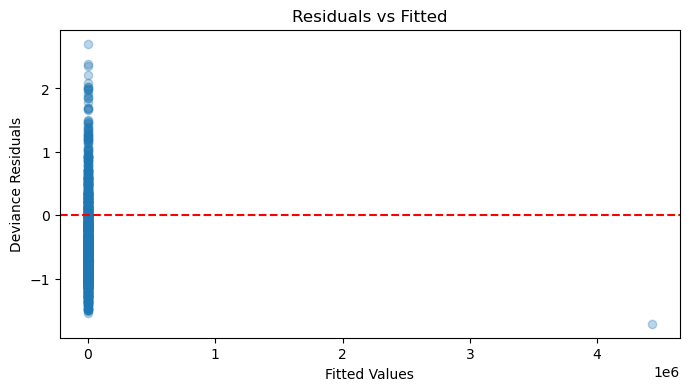

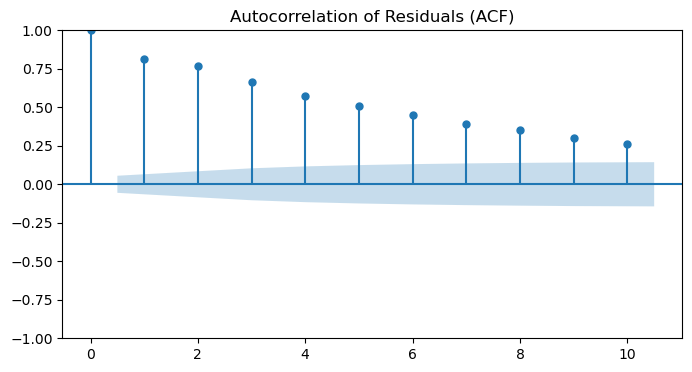

temprange RR range: 0.166 to 227372750332744832.000


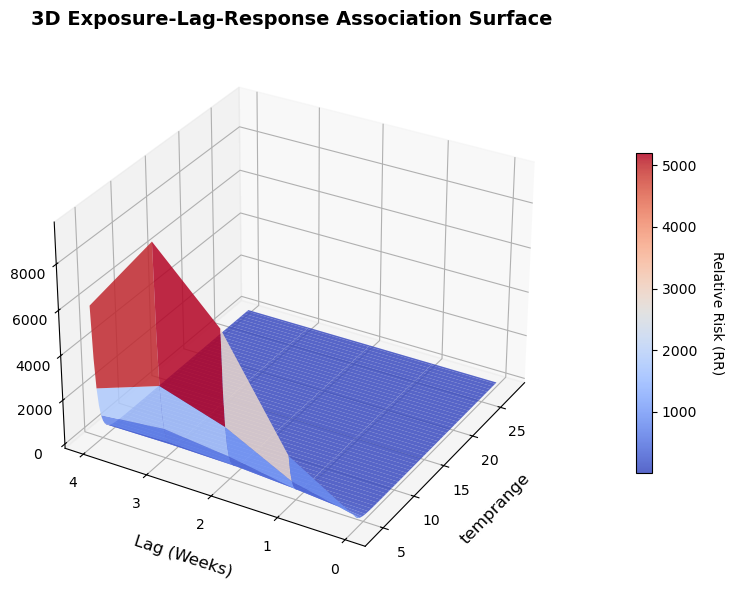

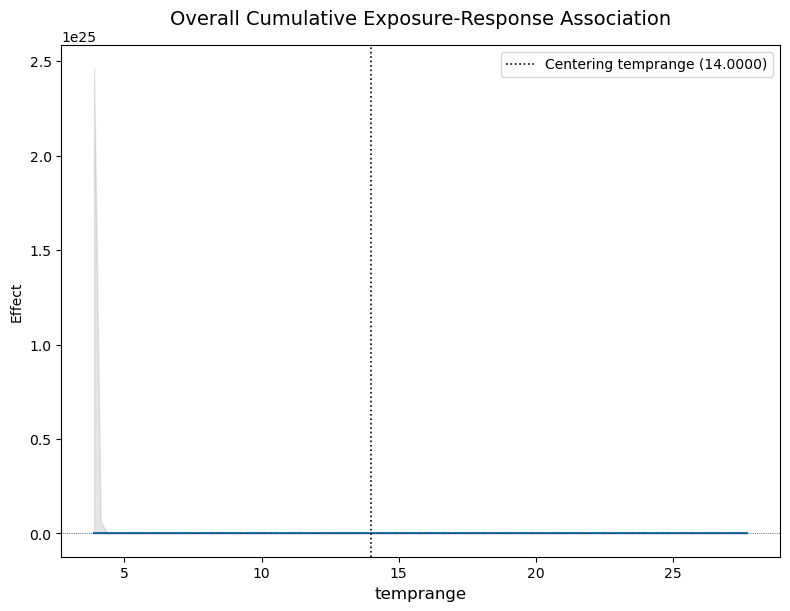

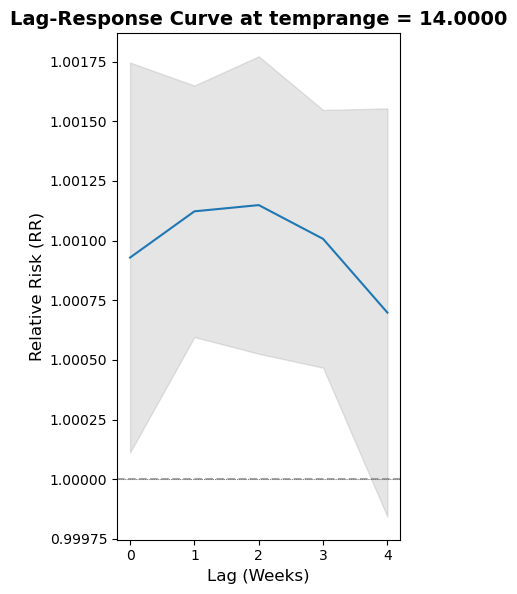

In [ ]:
# Testing 
tar_var = "H1"

exp = mete_col[0]
exp_col_list = [exp]
display(Markdown(f"**{'='*30} {exp} {'='*30}**"))
result, pred, model_data, cb_list = DLNM(df, max_lag=4, tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list, bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst, cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=["bic", "gcv"])


**============================== temp ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9343.14
BIC for (2, 3, 2, 4): 9366.02
BIC for (2, 3, 2, 5): 9385.09
BIC for (2, 3, 2, 6): 9385.09
BIC for (2, 3, 3, 3): 9366.02
BIC for (2, 3, 3, 4): 9366.02
BIC for (2, 3, 3, 5): 9385.09
BIC for (2, 3, 3, 6): 9385.09
BIC for (2, 4, 2, 3): 9358.01
BIC for (2, 4, 2, 4): 9388.67
BIC for (2, 4, 2, 5): 9416.18
BIC for (2, 4, 2, 6): 9416.18
BIC for (2, 4, 3, 3): 9388.67
BIC for (2, 4, 3, 4): 9388.67
BIC for (2, 4, 3, 5): 9416.18
BIC for (2, 4, 3, 6): 9416.18
BIC for (2, 5, 2, 3): 9440.72
BIC for (2, 5, 2, 4): 9448.73
BIC for (2, 5, 2, 5): 9484.08
BIC for (2, 5, 2, 6): 9484.08
BIC for (2, 5, 3, 3): 9448.73
BIC for (2, 5, 3, 4): 9448.73
BIC for (2, 5, 3, 5): 9484.08
BIC for (2, 5, 3, 6): 9484.08
BIC for (2, 6, 2, 3): 9440.77
BIC for (2, 6, 2, 4): 9474.78
BIC for (2, 6, 2, 5): 9518.54
BIC for (2, 6, 2, 6): 9518.54
BIC for (2, 6, 3, 3): 9486.34
BIC for (2, 6, 3, 4): 9486.34
BIC for (2, 6, 3, 5): 9518.54
BIC for (2, 6, 3, 6):

,alpha,AIC,BIC,GCV,EDF
BIC,"[152.864519480878, 269.53241686968937, 221.163...",9112.084418,9201.748832,1.028586,17.478108
GCV,"[152.864519480878, 269.53241686968937, 221.163...",9112.084418,9201.748832,1.028586,17.478108
KFold,"(15848.931924611108, 25.118864315095795, 5.011...",9157.66963,9294.078125,1.043977,26.589839



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion parameter   1.0: 
	- Pearson ration = 3.5500 
	- BIC = 9201.7488
Dispersion parameter   2.0: 
	- Pearson ration = 2.0527 
	- BIC = 8772.3015
Dispersion parameter   5.0: 
	- Pearson ration = 1.0147 
	- BIC = 9144.8338
Dispersion parameter  10.0: 
	- Pearson ration = 0.5658 
	- BIC = 9592.1954
Dispersion parameter  20.0: 
	- Pearson ration = 0.3110 
	- BIC = 10378.3945

Best dispersion parameter: 5.0 (Pearson ratio = 1.0147)


=============== Final model summary ===============
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1249
Model:                         GLMGam   Df Residuals:                  1218.59
Model Family:        NegativeBinomial   Df Model:                        29.41
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-

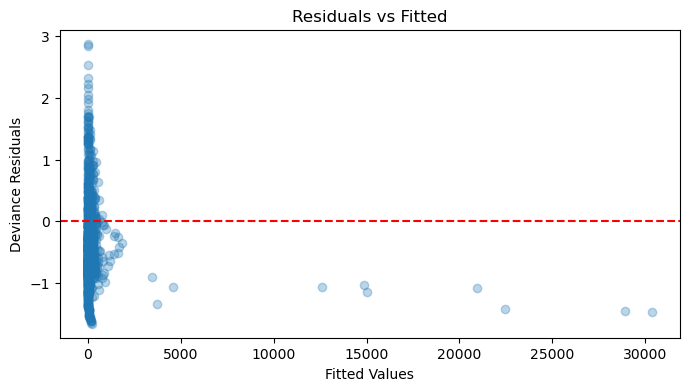

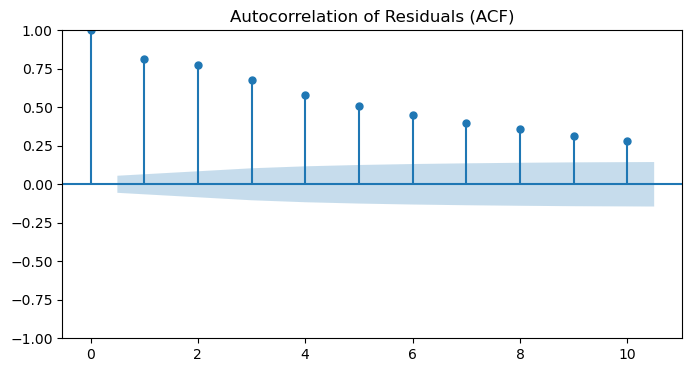

temp RR range: 0.781 to 520528.208


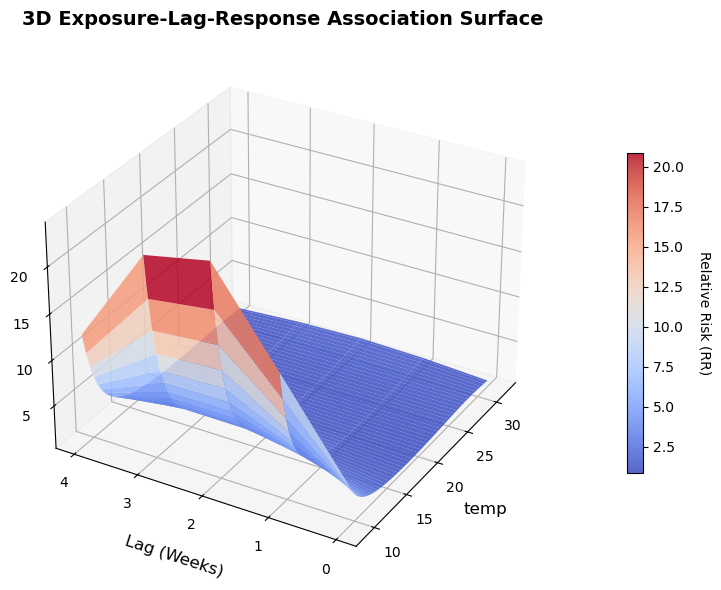

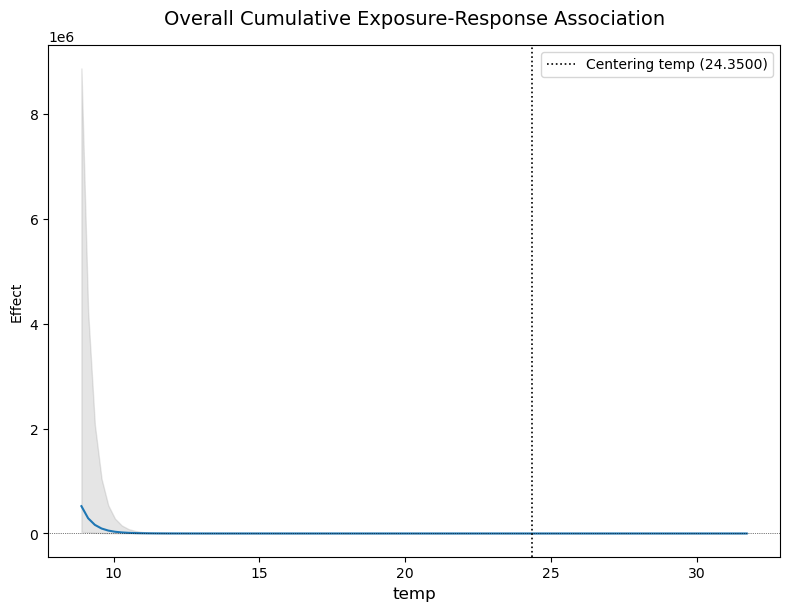

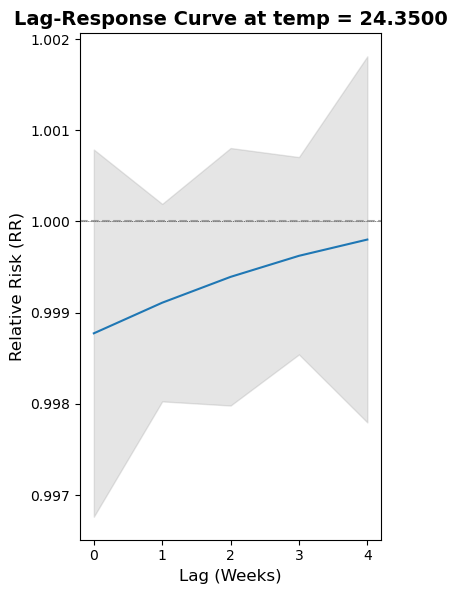

**============================== RH ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9699.85
BIC for (2, 3, 2, 4): 9719.27
BIC for (2, 3, 2, 5): 9738.22
BIC for (2, 3, 2, 6): 9738.22
BIC for (2, 3, 3, 3): 9719.27
BIC for (2, 3, 3, 4): 9719.27
BIC for (2, 3, 3, 5): 9738.22
BIC for (2, 3, 3, 6): 9738.22
BIC for (2, 4, 2, 3): 9677.96
BIC for (2, 4, 2, 4): 9701.63
BIC for (2, 4, 2, 5): 9725.07
BIC for (2, 4, 2, 6): 9725.07
BIC for (2, 4, 3, 3): 9701.63
BIC for (2, 4, 3, 4): 9701.63
BIC for (2, 4, 3, 5): 9725.07
BIC for (2, 4, 3, 6): 9725.07
BIC for (2, 5, 2, 3): 9621.54
BIC for (2, 5, 2, 4): 9652.26
BIC for (2, 5, 2, 5): 9683.22
BIC for (2, 5, 2, 6): 9683.22
BIC for (2, 5, 3, 3): 9652.26
BIC for (2, 5, 3, 4): 9652.26
BIC for (2, 5, 3, 5): 9683.22
BIC for (2, 5, 3, 6): 9683.22
BIC for (2, 6, 2, 3): 9561.97
BIC for (2, 6, 2, 4): 9597.34
BIC for (2, 6, 2, 5): 9633.17
BIC for (2, 6, 2, 6): 9633.17
BIC for (2, 6, 3, 3): 9597.34
BIC for (2, 6, 3, 4): 9597.34
BIC for (2, 6, 3, 5): 9633.17
BIC for (2, 6, 3, 6):

,alpha,AIC,BIC,GCV,EDF
BIC,"[238.75342810398908, 234.02926339360855, 239.8...",9081.093117,9327.327445,1.081527,47.997973
GCV,"[238.75342810398908, 234.02926339360855, 239.8...",9081.093117,9327.327445,1.081527,47.997973
KFold,"(25.118864315095795, 630.957344480193, 25.1188...",9044.91807,9218.339302,1.05641,33.804659



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion parameter   1.0: 
	- Pearson ration = 6.8781 
	- BIC = 9327.3274
Dispersion parameter   2.0: 
	- Pearson ration = 3.1366 
	- BIC = 8988.0564
Dispersion parameter   5.0: 
	- Pearson ration = 1.0360 
	- BIC = 9097.2960
Dispersion parameter  10.0: 
	- Pearson ration = 0.5266 
	- BIC = 9738.7768
Dispersion parameter  20.0: 
	- Pearson ration = 0.2979 
	- BIC = 10419.6234

Best dispersion parameter: 5.0 (Pearson ratio = 1.0360)


=============== Final model summary ===============
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1249
Model:                         GLMGam   Df Residuals:                  1228.43
Model Family:        NegativeBinomial   Df Model:                        19.57
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-

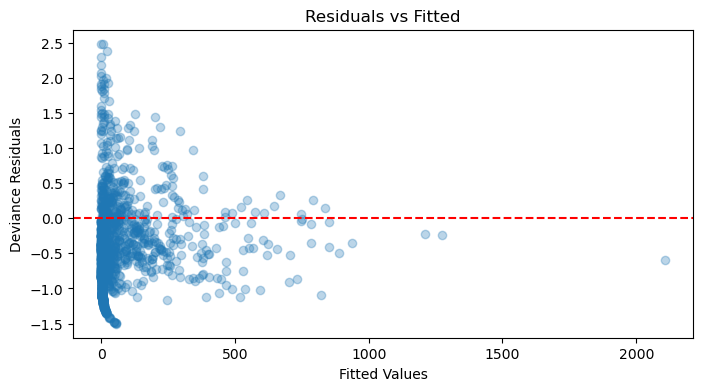

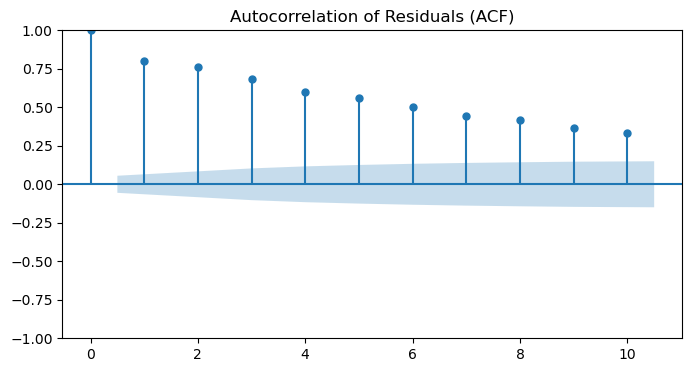

RH RR range: 0.211 to 6894.299


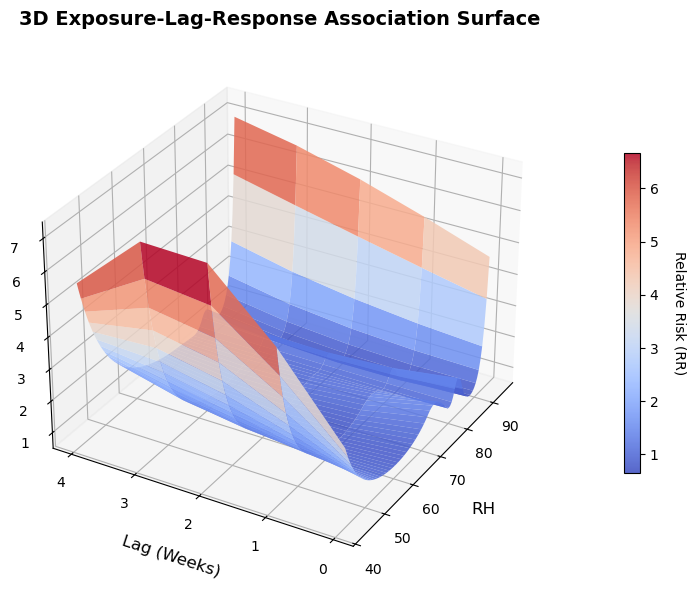

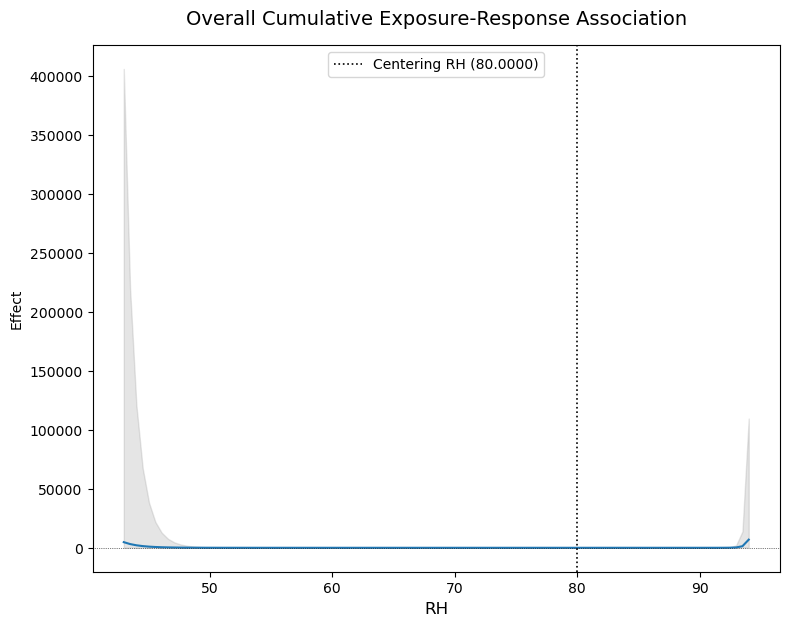

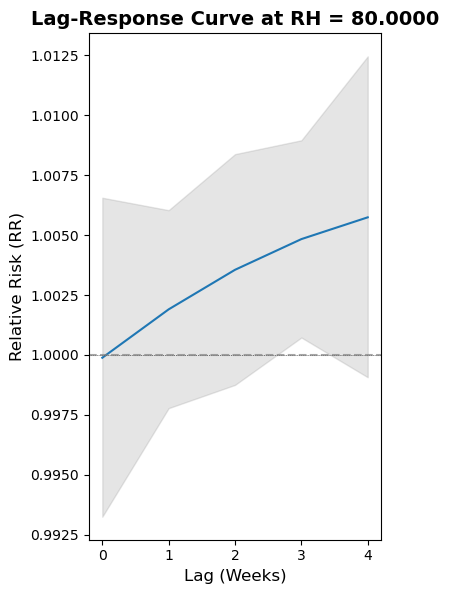

**============================== SR ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9644.50
BIC for (2, 3, 2, 4): 9667.55
BIC for (2, 3, 2, 5): 9691.60
BIC for (2, 3, 2, 6): 9691.60
BIC for (2, 3, 3, 3): 9667.55
BIC for (2, 3, 3, 4): 9667.55
BIC for (2, 3, 3, 5): 9691.60
BIC for (2, 3, 3, 6): 9691.60
BIC for (2, 4, 2, 3): 9662.65
BIC for (2, 4, 2, 4): 9692.01
BIC for (2, 4, 2, 5): 9720.67
BIC for (2, 4, 2, 6): 9720.67
BIC for (2, 4, 3, 3): 9692.01
BIC for (2, 4, 3, 4): 9692.01
BIC for (2, 4, 3, 5): 9720.67
BIC for (2, 4, 3, 6): 9720.67
BIC for (2, 5, 2, 3): 9675.03
BIC for (2, 5, 2, 4): 9710.62
BIC for (2, 5, 2, 5): 9745.01
BIC for (2, 5, 2, 6): 9745.01
BIC for (2, 5, 3, 3): 9710.62
BIC for (2, 5, 3, 4): 9710.62
BIC for (2, 5, 3, 5): 9745.01
BIC for (2, 5, 3, 6): 9745.01
BIC for (2, 6, 2, 3): 9676.54
BIC for (2, 6, 2, 4): 9719.09
BIC for (2, 6, 2, 5): 9761.94
BIC for (2, 6, 2, 6): 9761.94
BIC for (2, 6, 3, 3): 9719.09
BIC for (2, 6, 3, 4): 9719.09
BIC for (2, 6, 3, 5): 9761.94
BIC for (2, 6, 3, 6):

,alpha,AIC,BIC,GCV,EDF
BIC,"[200.00000000219745, 228.32619828379694, 199.9...",9139.643753,9101.045674,0.98806,-7.523848
GCV,"[170.1064361106978, 242.17134036646075, 209.02...",9102.653382,8967.640013,0.959153,-26.31789
KFold,"(398107.1705534969, 630.957344480193, 1.0)",9211.057998,9336.895831,1.040466,24.529321



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion parameter   1.0: 
	- Pearson ration = 13.3101 
	- BIC = 9101.0457
Dispersion parameter   2.0: 
	- Pearson ration = 4.8982 
	- BIC = 9102.4976
Dispersion parameter   5.0: 
	- Pearson ration = 1.0842 
	- BIC = 9174.1316
Dispersion parameter  10.0: 
	- Pearson ration = 0.5291 
	- BIC = 9652.8120
Dispersion parameter  20.0: 
	- Pearson ration = 0.2701 
	- BIC = 10400.3786

Best dispersion parameter: 5.0 (Pearson ratio = 1.0842)


=============== Final model summary ===============
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1249
Model:                         GLMGam   Df Residuals:                  1223.35
Model Family:        NegativeBinomial   Df Model:                        24.65
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log

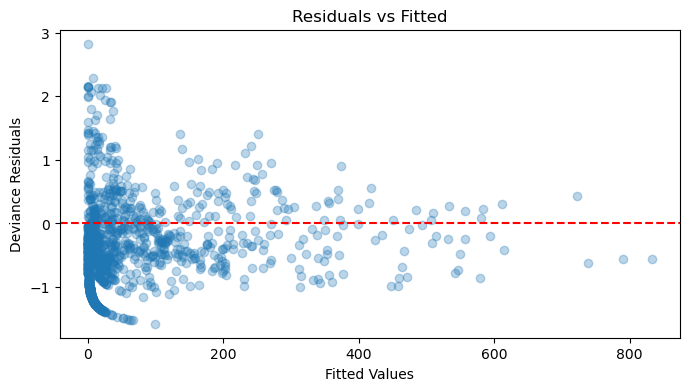

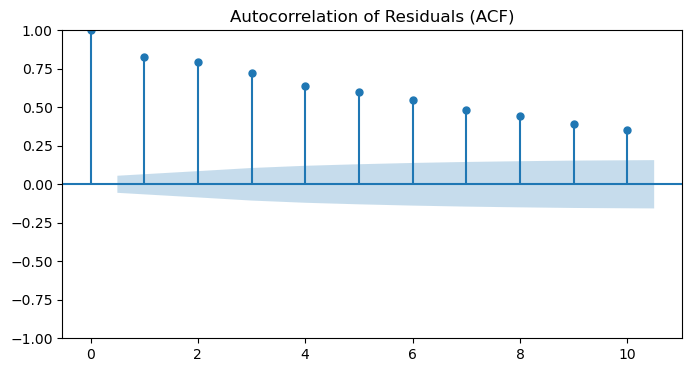

SR RR range: 0.025 to 18.305


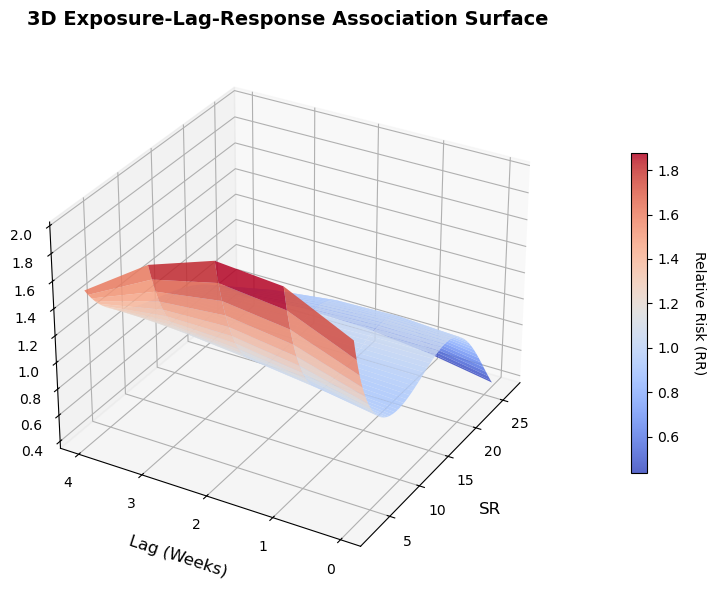

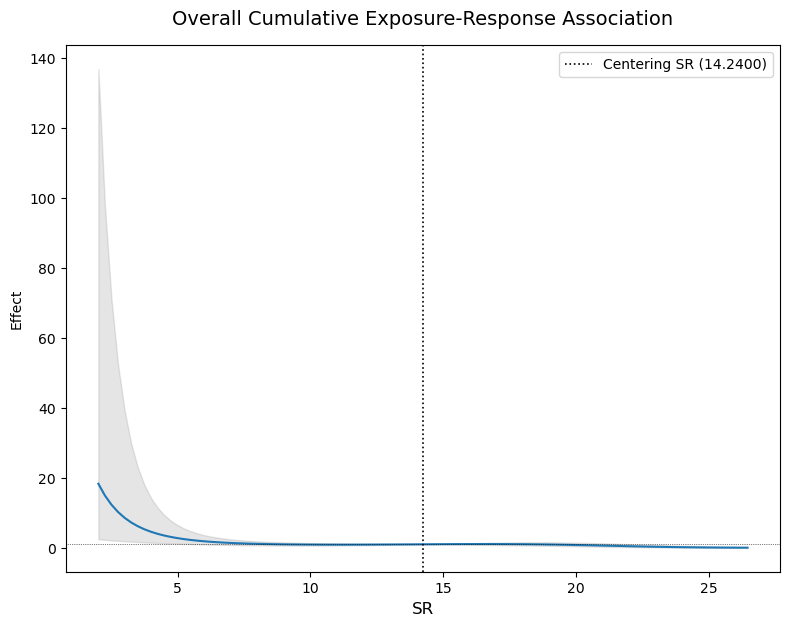

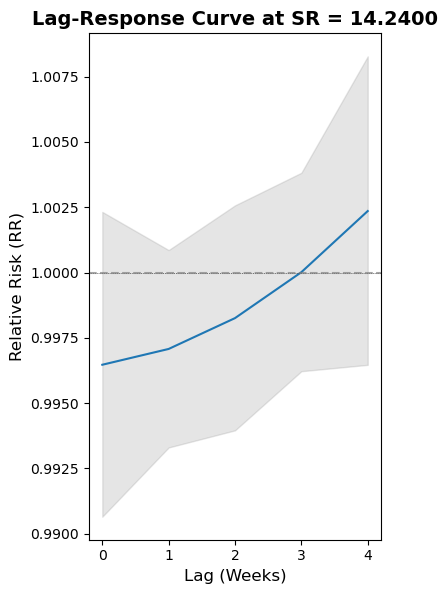

**============================== AP ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9491.34
BIC for (2, 3, 2, 4): 9514.16
BIC for (2, 3, 2, 5): 9534.27
BIC for (2, 3, 2, 6): 9534.27
BIC for (2, 3, 3, 3): 9514.16
BIC for (2, 3, 3, 4): 9514.16
BIC for (2, 3, 3, 5): 9534.27
BIC for (2, 3, 3, 6): 9534.27
BIC for (2, 4, 2, 3): 9519.46
BIC for (2, 4, 2, 4): 9548.72
BIC for (2, 4, 2, 5): 9597.12
BIC for (2, 4, 2, 6): 9597.12
BIC for (2, 4, 3, 3): 9548.72
BIC for (2, 4, 3, 4): 9548.72
BIC for (2, 4, 3, 5): 9597.12
BIC for (2, 4, 3, 6): 9597.12
BIC for (2, 5, 2, 3): 9533.72
BIC for (2, 5, 2, 4): 9569.08
BIC for (2, 5, 2, 5): 9631.46
BIC for (2, 5, 2, 6): 9631.46
BIC for (2, 5, 3, 3): 9569.08
BIC for (2, 5, 3, 4): 9569.08
BIC for (2, 5, 3, 5): 9631.46
BIC for (2, 5, 3, 6): 9631.46
BIC for (2, 6, 2, 3): 9519.74
BIC for (2, 6, 2, 4): 9562.27
BIC for (2, 6, 2, 5): 9626.81
BIC for (2, 6, 2, 6): 9626.81
BIC for (2, 6, 3, 3): 9562.27
BIC for (2, 6, 3, 4): 9562.27
BIC for (2, 6, 3, 5): 9626.81
BIC for (2, 6, 3, 6):

,alpha,AIC,BIC,GCV,EDF
BIC,"[260.6635113307704, 200.0012062420254, 199.999...",9339.410178,9337.764076,0.999486,-0.320871
GCV,"[260.6635113307704, 200.0012062420254, 199.999...",9339.410178,9337.764076,0.999486,-0.320871
KFold,"(10000000.0, 3162.2776601683795, 15848.9319246...",9752.174156,9858.916639,1.034169,20.807102



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion parameter   1.0: 
	- Pearson ration = 5.4114 
	- BIC = 9337.7641
Dispersion parameter   2.0: 
	- Pearson ration = 2.2808 
	- BIC = 8926.9927
Dispersion parameter   5.0: 
	- Pearson ration = 0.9512 
	- BIC = 9207.4620
Dispersion parameter  10.0: 
	- Pearson ration = 0.4995 
	- BIC = 9691.0748
Dispersion parameter  20.0: 
	- Pearson ration = 0.2606 
	- BIC = 10390.2796

Best dispersion parameter: 5.0 (Pearson ratio = 0.9512)


=============== Final model summary ===============
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1249
Model:                         GLMGam   Df Residuals:                  1220.95
Model Family:        NegativeBinomial   Df Model:                        27.05
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-

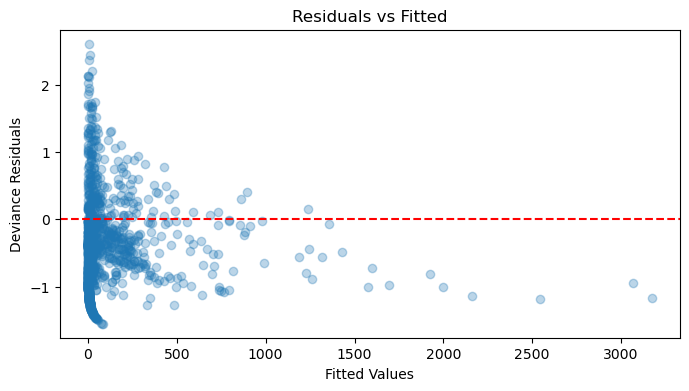

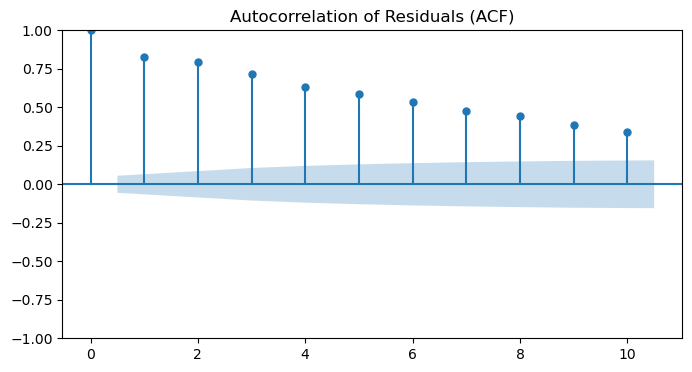

AP RR range: 0.636 to 1542.927


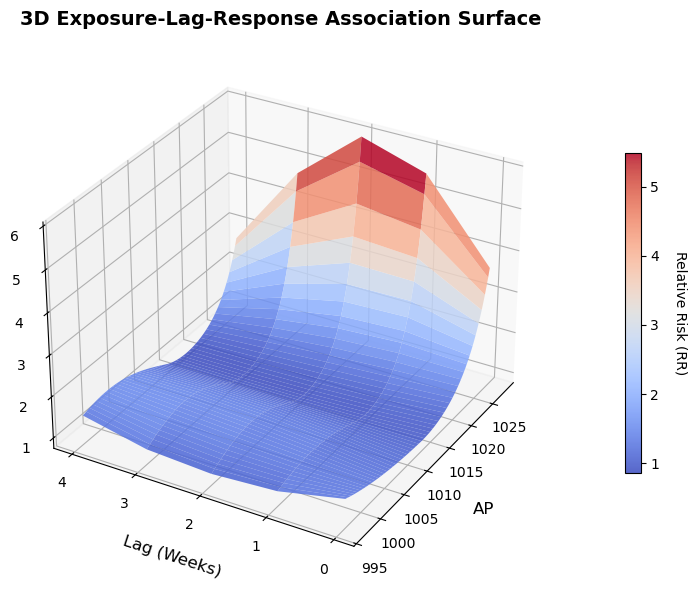

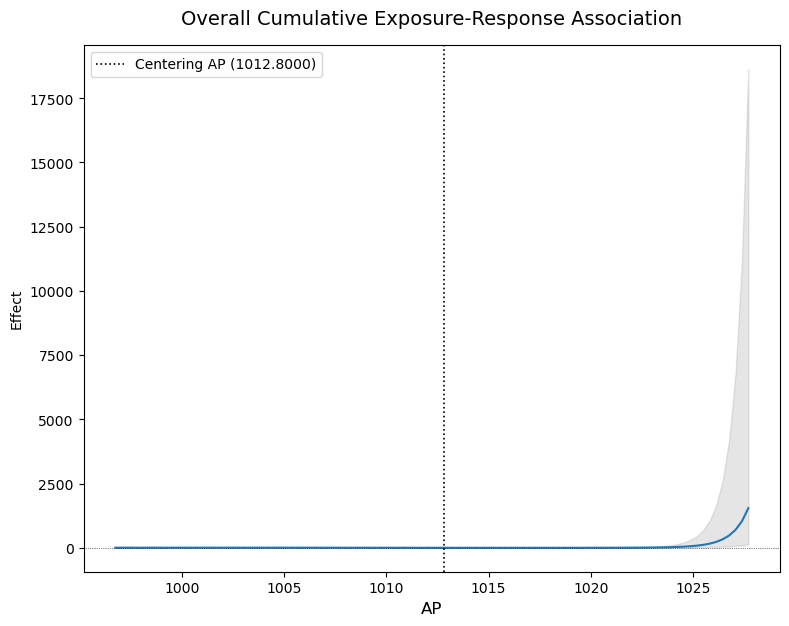

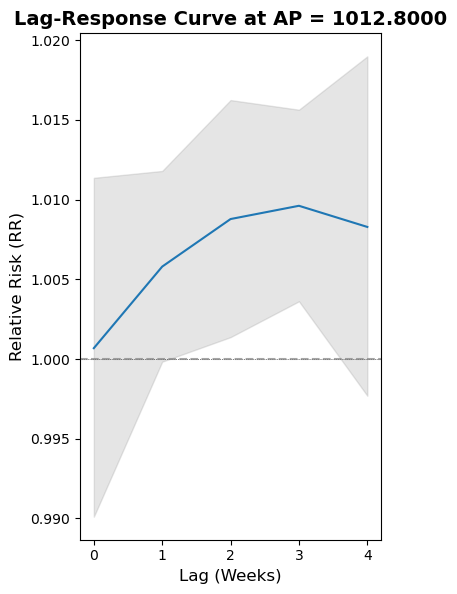

**============================== DPT ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9358.94
BIC for (2, 3, 2, 4): 9377.97
BIC for (2, 3, 2, 5): 9395.21
BIC for (2, 3, 2, 6): 9395.21
BIC for (2, 3, 3, 3): 9377.97
BIC for (2, 3, 3, 4): 9377.97
BIC for (2, 3, 3, 5): 9395.21
BIC for (2, 3, 3, 6): 9395.21
BIC for (2, 4, 2, 3): 9366.49
BIC for (2, 4, 2, 4): 9390.16
BIC for (2, 4, 2, 5): 9413.12
BIC for (2, 4, 2, 6): 9413.12
BIC for (2, 4, 3, 3): 9390.16
BIC for (2, 4, 3, 4): 9390.16
BIC for (2, 4, 3, 5): 9413.12
BIC for (2, 4, 3, 6): 9413.12
BIC for (2, 5, 2, 3): 9387.58
BIC for (2, 5, 2, 4): 9418.17
BIC for (2, 5, 2, 5): 9447.02
BIC for (2, 5, 2, 6): 9447.02
BIC for (2, 5, 3, 3): 9418.17
BIC for (2, 5, 3, 4): 9418.17
BIC for (2, 5, 3, 5): 9447.02
BIC for (2, 5, 3, 6): 9447.02
BIC for (2, 6, 2, 3): 9409.98
BIC for (2, 6, 2, 4): 9448.69
BIC for (2, 6, 2, 5): 9484.34
BIC for (2, 6, 2, 6): 9484.34
BIC for (2, 6, 3, 3): 9448.69
BIC for (2, 6, 3, 4): 9448.69
BIC for (2, 6, 3, 5): 9484.34
BIC for (2, 6, 3, 6):

,alpha,AIC,BIC,GCV,EDF
BIC,"[190.38737552648416, 244.3542676551454, 189.32...",9136.392149,9437.315407,1.100986,58.658378
GCV,"[162.85613945592186, 247.60802527005828, 223.2...",8893.805031,8569.558028,0.905986,-63.20483
KFold,"(630.957344480193, 5.011872336272722, 10000000.0)",9447.684521,9562.314741,1.036764,22.344643



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion parameter   1.0: 
	- Pearson ration = 3.2641 
	- BIC = 9437.3154
Dispersion parameter   2.0: 
	- Pearson ration = 1.8706 
	- BIC = 8874.3972
Dispersion parameter   5.0: 
	- Pearson ration = 0.9184 
	- BIC = 9224.4032
Dispersion parameter  10.0: 
	- Pearson ration = 0.5029 
	- BIC = 9574.5535
Dispersion parameter  20.0: 
	- Pearson ration = 0.2774 
	- BIC = 10387.3316

Best dispersion parameter: 5.0 (Pearson ratio = 0.9184)


=============== Final model summary ===============
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1249
Model:                         GLMGam   Df Residuals:                  1206.19
Model Family:        NegativeBinomial   Df Model:                        41.81
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-

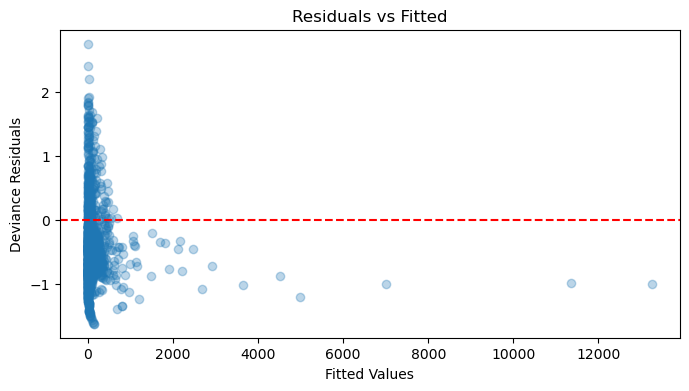

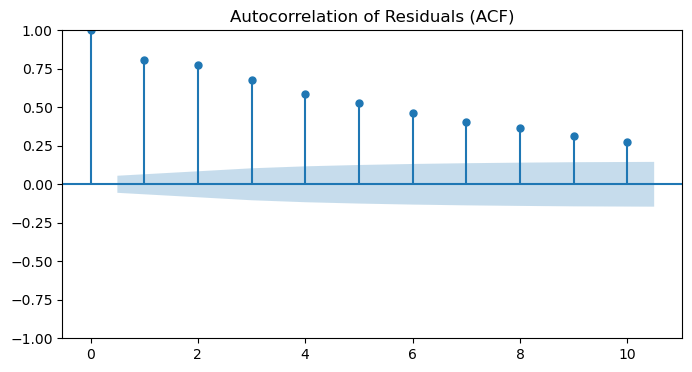

DPT RR range: 0.521 to 33620.233


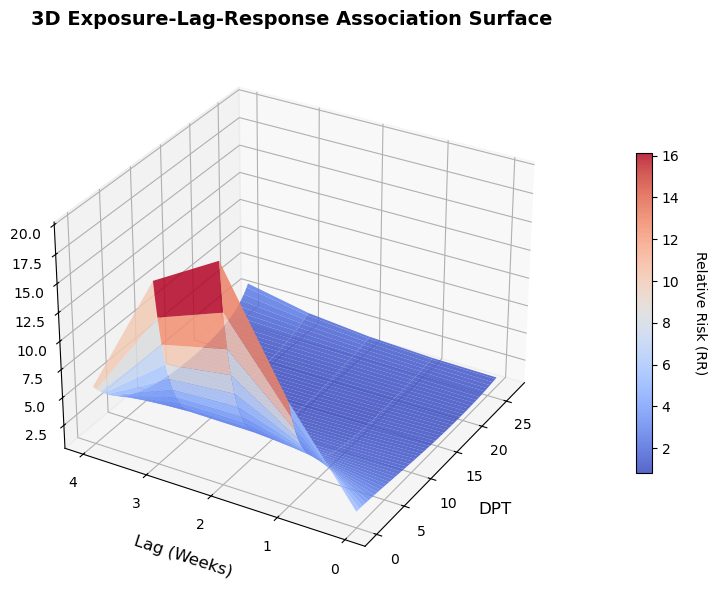

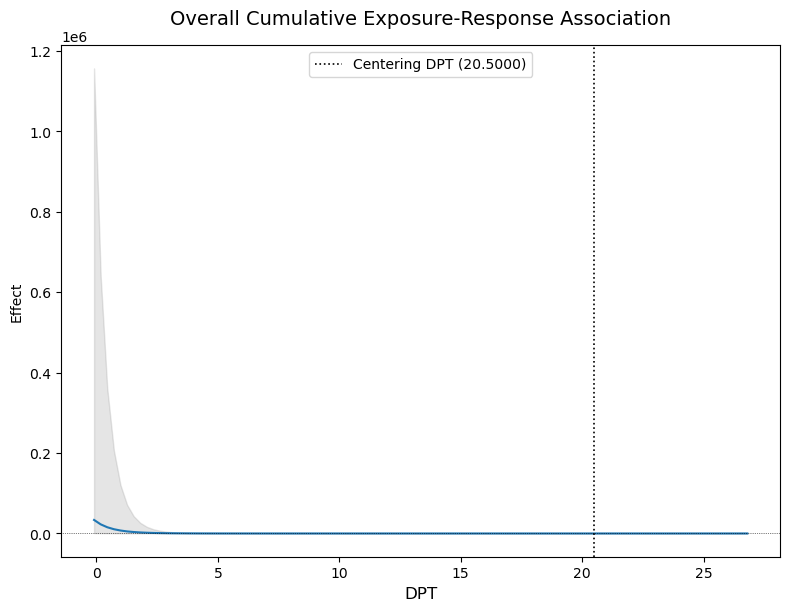

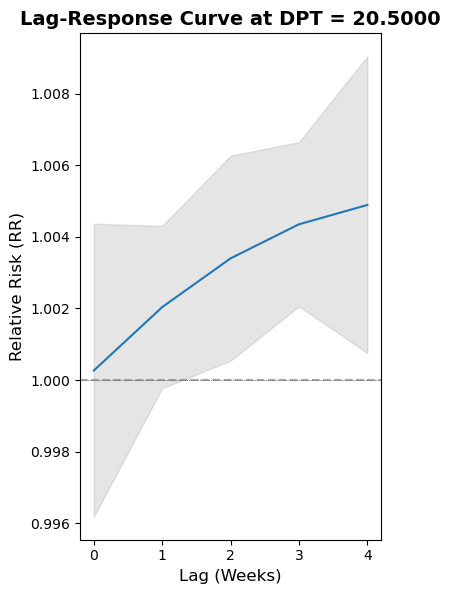

**============================== WS ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9677.60
BIC for (2, 3, 2, 4): 9695.44
BIC for (2, 3, 2, 5): 9714.21
BIC for (2, 3, 2, 6): 9714.21
BIC for (2, 3, 3, 3): 9695.44
BIC for (2, 3, 3, 4): 9695.44
BIC for (2, 3, 3, 5): 9714.21
BIC for (2, 3, 3, 6): 9714.21
BIC for (2, 4, 2, 3): 9690.02
BIC for (2, 4, 2, 4): 9713.93
BIC for (2, 4, 2, 5): 9739.44
BIC for (2, 4, 2, 6): 9739.44
BIC for (2, 4, 3, 3): 9713.93
BIC for (2, 4, 3, 4): 9713.93
BIC for (2, 4, 3, 5): 9739.44
BIC for (2, 4, 3, 6): 9739.44
BIC for (2, 5, 2, 3): 9654.94
BIC for (2, 5, 2, 4): 9688.67
BIC for (2, 5, 2, 5): 9719.96
BIC for (2, 5, 2, 6): 9719.96
BIC for (2, 5, 3, 3): 9688.67
BIC for (2, 5, 3, 4): 9688.67
BIC for (2, 5, 3, 5): 9719.96
BIC for (2, 5, 3, 6): 9719.96
BIC for (2, 6, 2, 3): 9671.80
BIC for (2, 6, 2, 4): 9710.58
BIC for (2, 6, 2, 5): 9745.79
BIC for (2, 6, 2, 6): 9745.79
BIC for (2, 6, 3, 3): 9710.58
BIC for (2, 6, 3, 4): 9710.58
BIC for (2, 6, 3, 5): 9745.79
BIC for (2, 6, 3, 6):

,alpha,AIC,BIC,GCV,EDF
BIC,"[308.5775208143524, 156.99511886586524, 220.48...",9282.371174,9563.435801,1.09386,54.787374
GCV,"[308.5775208143524, 156.99511886586524, 220.48...",9282.371174,9563.435801,1.09386,54.787374
KFold,"(25.118864315095795, 5.011872336272722, 3162.2...",9391.969091,9531.026575,1.04486,27.106201



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion parameter   1.0: 
	- Pearson ration = 6.8583 
	- BIC = 9563.4358
Dispersion parameter   2.0: 
	- Pearson ration = 3.1029 
	- BIC = 8756.4865
Dispersion parameter   5.0: 
	- Pearson ration = 1.0977 
	- BIC = 9219.9564
Dispersion parameter  10.0: 
	- Pearson ration = 0.5539 
	- BIC = 9683.1084
Dispersion parameter  20.0: 
	- Pearson ration = 0.2835 
	- BIC = 10418.0176

Best dispersion parameter: 5.0 (Pearson ratio = 1.0977)


=============== Final model summary ===============
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1249
Model:                         GLMGam   Df Residuals:                  1216.51
Model Family:        NegativeBinomial   Df Model:                        31.49
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-

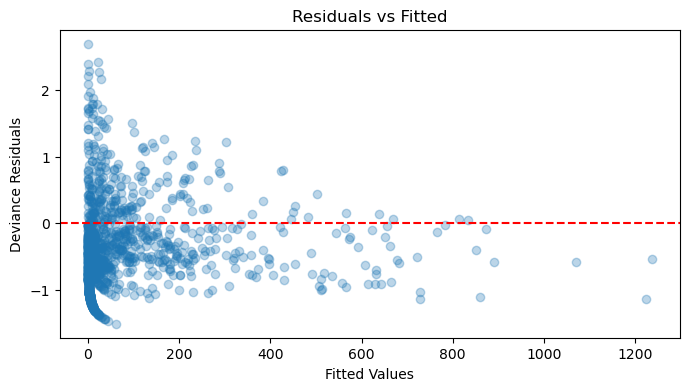

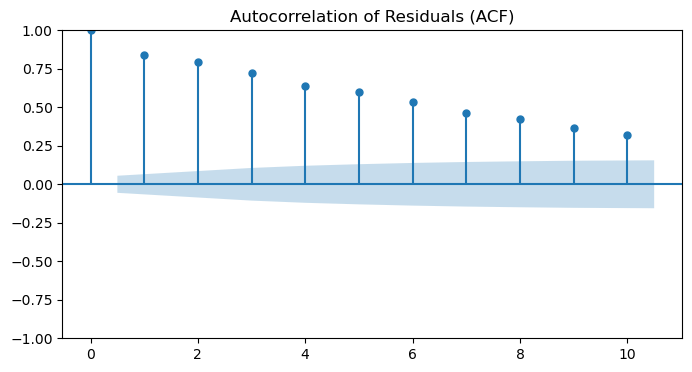

WS RR range: 0.592 to 112.237


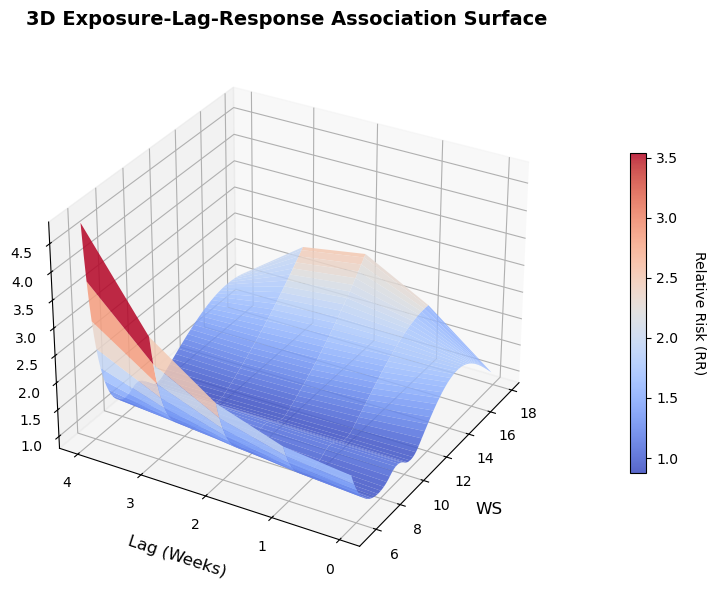

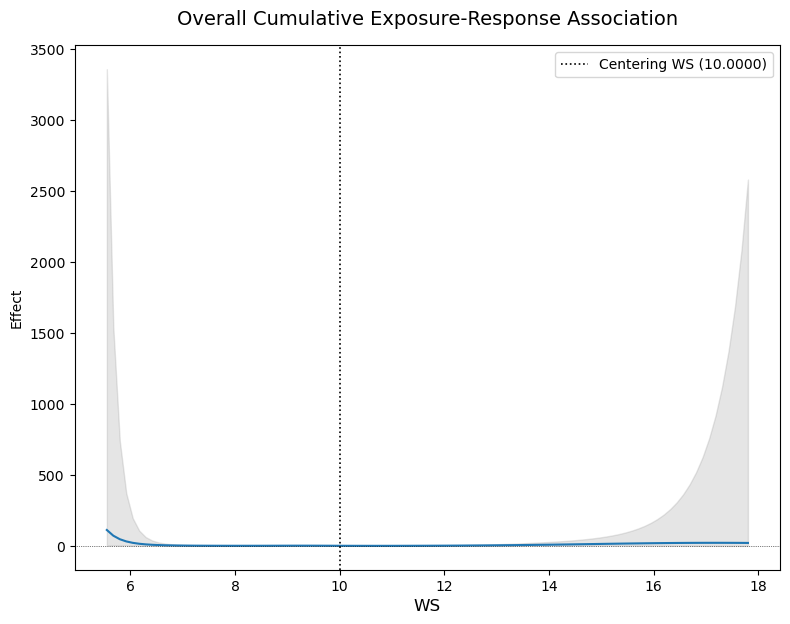

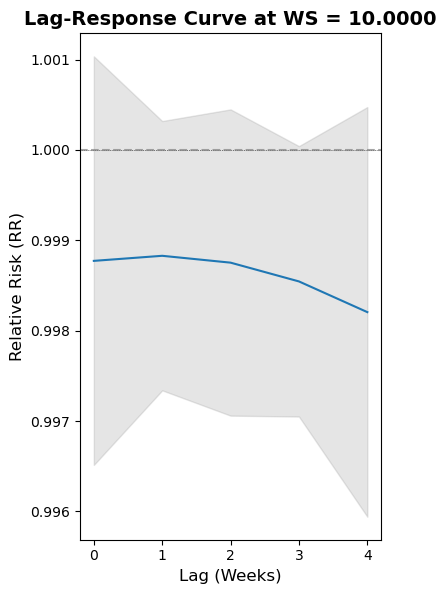

**============================== UV ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9645.02
BIC for (2, 3, 2, 4): 9666.80
BIC for (2, 3, 2, 5): 9689.92
BIC for (2, 3, 2, 6): 9689.92
BIC for (2, 3, 3, 3): 9666.80
BIC for (2, 3, 3, 4): 9666.80
BIC for (2, 3, 3, 5): 9689.92
BIC for (2, 3, 3, 6): 9689.92
BIC for (2, 4, 2, 3): 9635.21
BIC for (2, 4, 2, 4): 9666.52
BIC for (2, 4, 2, 5): 9697.90
BIC for (2, 4, 2, 6): 9697.90
BIC for (2, 4, 3, 3): 9666.52
BIC for (2, 4, 3, 4): 9666.52
BIC for (2, 4, 3, 5): 9697.90
BIC for (2, 4, 3, 6): 9697.90
BIC for (2, 5, 2, 3): 9613.36
BIC for (2, 5, 2, 4): 9652.95
BIC for (2, 5, 2, 5): 9693.29
BIC for (2, 5, 2, 6): 9693.29
BIC for (2, 5, 3, 3): 9652.95
BIC for (2, 5, 3, 4): 9652.95
BIC for (2, 5, 3, 5): 9693.29
BIC for (2, 5, 3, 6): 9693.29
BIC for (2, 6, 2, 3): 9615.45
BIC for (2, 6, 2, 4): 9659.94
BIC for (2, 6, 2, 5): 9705.37
BIC for (2, 6, 2, 6): 9705.37
BIC for (2, 6, 3, 3): 9659.94
BIC for (2, 6, 3, 4): 9659.94
BIC for (2, 6, 3, 5): 9705.37
BIC for (2, 6, 3, 6):

,alpha,AIC,BIC,GCV,EDF
BIC,"[252.02458079799777, 206.27749860660137, 203.1...",9203.381708,9301.507019,1.031347,19.127374
GCV,"[259.75736057046106, 201.0457596766612, 199.52...",9378.259214,9925.681062,1.195558,106.707863
KFold,"(1995262.3149688789, 5.011872336272722, 630.95...",9246.618808,9314.467843,1.021519,13.225679



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion parameter   1.0: 
	- Pearson ration = 3.8812 
	- BIC = 9301.5070
Dispersion parameter   2.0: 
	- Pearson ration = 2.2992 
	- BIC = 9161.5286
Dispersion parameter   5.0: 
	- Pearson ration = 0.9058 
	- BIC = 9176.2079
Dispersion parameter  10.0: 
	- Pearson ration = 0.4837 
	- BIC = 9680.9620
Dispersion parameter  20.0: 
	- Pearson ration = 0.2568 
	- BIC = 10414.1907

Best dispersion parameter: 5.0 (Pearson ratio = 0.9058)


=============== Final model summary ===============
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1249
Model:                         GLMGam   Df Residuals:                  1219.61
Model Family:        NegativeBinomial   Df Model:                        28.39
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-

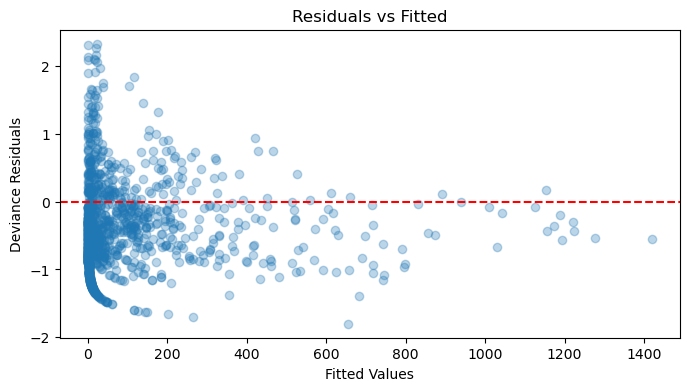

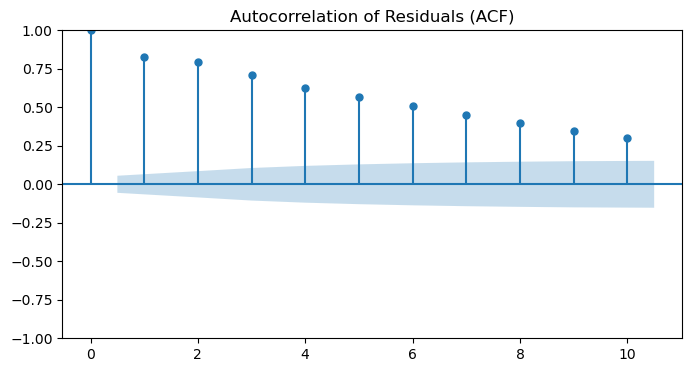

UV RR range: 0.000 to 2254.321


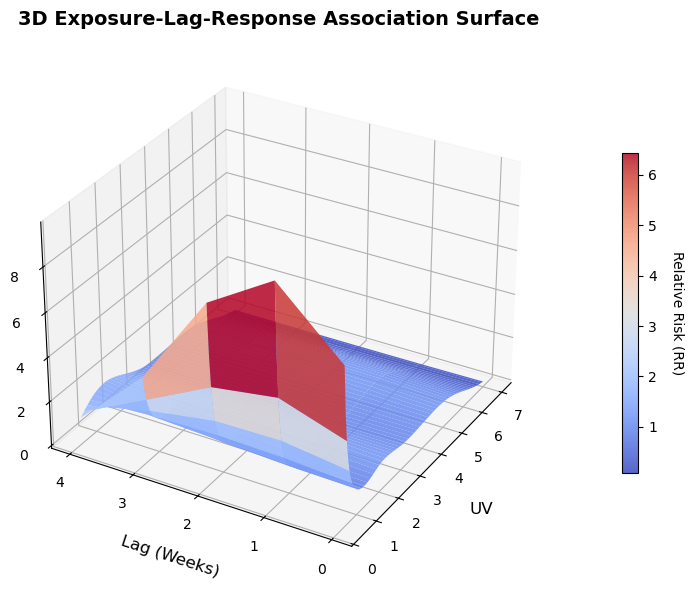

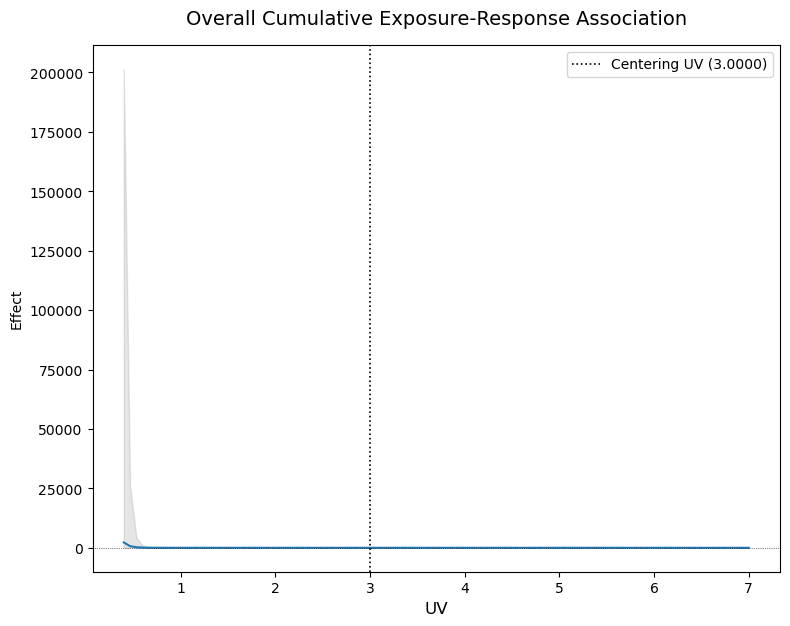

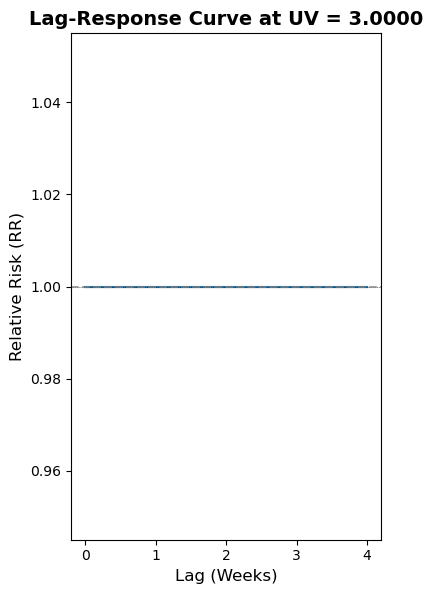

In [ ]:
tar_var = "H1"

for exp in mete_col[1:]:
    exp_col_list = [exp]
    display(Markdown(f"**{'='*30} {exp} {'='*30}**"))
    result, pred, model_data, cb_list = DLNM(df, max_lag=4, tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list, bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst, cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=["bic", "gcv"])
